# Random Forest balanceado

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro

---

### Abstract

Este notebook entrena un **Random Forest** de clasificación con balanceo de clases por pesos (`class_weight="balanced"`), como el random forest balanceado de Almeida et al. (2026); el random forest también aparece en Khan et al. (2022) y Ranjbar et al. (2023). Un Random Forest entrena muchos árboles de decisión, cada uno con una muestra distinta de los datos y viendo solo una parte de las columnas en cada corte, y promedia sus votos. A diferencia de la regresión logística, puede capturar relaciones no lineales e interacciones entre variables sin especificarlas. Usa las 9 features del EDA, casos completos y la partición temporal. El tamaño mínimo de las hojas, la fracción de columnas por corte y la fracción de filas por árbol se eligen por AUC-PR en validación; el test (2024–2025) se usa una sola vez. Se compara con el baseline (regresión logística simple).

**Resultado principal:** se eligió `min_samples_leaf = 50`, `max_features = 0.5` y `max_samples = 0.3`. En el test (2024–2025) el Random Forest balanceado alcanza AUC-ROC 0.911 y AUC-PR 0.679, apenas por encima del baseline (0.908 y 0.677). Con el umbral 0.5 detecta 79% de los casos de bajo peso con una precisión de 0.34.

### Estructura del notebook

1. Configuración del entorno
2. Datos y partición temporal
3. Ajuste de hiperparámetros (min_samples_leaf × max_features × max_samples)
4. Modelo final y evaluación en test
5. Interpretación
6. Limitaciones

## 1. Configuración del entorno

El notebook funciona en Google Colab y en local, igual que el EDA. En Colab clona o actualiza el repositorio; en local asume que se ejecuta desde `proyecto/notebooks/`. Todo el preprocesamiento se importa de `src/preprocessing.py`, para que los cinco modelos usen exactamente los mismos datos y la misma partición.

> **Tiempo de ejecución:** la grilla de 12 bosques es la parte lenta (en Colab cada bosque tardó entre 1 y 6.5 minutos, y la grilla completa unos 35 minutos). Se usa el entorno estándar de CPU: el Random Forest de scikit-learn no usa GPU.

In [ ]:
import sys, gc, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasnai10/AI_Project.git"

if IN_COLAB:
    if not Path("/content/AI_Project").exists():
        !git clone -q {REPO_URL} /content/AI_Project
    else:
        !git -C /content/AI_Project pull -q
    ROOT = Path("/content/AI_Project/proyecto")
else:
    ROOT = Path.cwd().parent

sys.path.insert(0, str(ROOT))
from src.preprocessing import (cargar_cnv, limpiar, seleccionar_features, columnas_features,
                               dividir_temporal, construir_preprocesador, SEMILLA)

pd.set_option("display.float_format", "{:,.4f}".format)
print("Entorno:", "Colab" if IN_COLAB else "local", "| ROOT:", ROOT)

Entorno: Colab | ROOT: /content/AI_Project/proyecto


## 2. Datos y partición temporal

Se carga el CNV original desde `data/raw/dataset.zip` y se aplican `limpiar()` y `seleccionar_features()` (9 features, casos completos). La partición es la **temporal** definida en el EDA:

| Conjunto | Años | Uso |
|---|---|---|
| Train | 2015–2023 (80% al azar, estratificado) | Ajustar el modelo y el preprocesador |
| Validación | 2015–2023 (20% restante) | Elegir min_samples_leaf, max_features y max_samples |
| Test | 2024–2025 | Evaluación final, una sola vez |

El test simula el uso real: entrenar con el pasado y predecir el futuro. Su prevalencia (6.81%) es mayor que la de train (6.32%), así que la precisión y el F1 en test cambian de nivel aunque el modelo sea el mismo. Por eso los modelos se comparan sobre todo con métricas que no dependen de la prevalencia ni del umbral. 2025 llega hasta el 30/11/2025, sin diciembre.

In [ ]:
df_raw, _ = cargar_cnv(ruta_zip=ROOT / "data" / "raw" / "dataset.zip")
df = limpiar(df_raw)
del df_raw; gc.collect()

X, y = seleccionar_features(df, target="bajo_peso")
X_tr, X_val, X_te, y_tr, y_val, y_te = dividir_temporal(X, y, df["anio"])
anio = df["anio"]
resumen = pd.DataFrame({
    "años": [f"{anio[X_tr.index].min()}-{anio[X_tr.index].max()}",
             f"{anio[X_val.index].min()}-{anio[X_val.index].max()}",
             f"{anio[X_te.index].min()}-{anio[X_te.index].max()}"],
    "registros": [len(y_tr), len(y_val), len(y_te)],
    "casos_bajo_peso": [int(y_tr.sum()), int(y_val.sum()), int(y_te.sum())],
    "prevalencia_%": [y_tr.mean() * 100, y_val.mean() * 100, y_te.mean() * 100]},
    index=["train", "validación", "test"])
del X, y, df, anio; gc.collect()
cat_cols, num_cols = columnas_features()
resumen.round(2)

Cargado CNV_MINSA_CORTE_30112025.csv: 4,874,510 filas, 22 columnas | filas reparadas: 388 | descartadas: 0
limpiar(): 4,874,510 → 4,871,486 filas (eliminadas 3,024 sin peso válido) | prevalencia de bajo peso: 6.38%
target=bajo_peso | 9 features | casos completos: 4,764,960 de 4,871,486 (97.81%)


,años,registros,casos_bajo_peso,prevalencia_%
train,2015-2023,3237829,204500,6.3200
validación,2015-2023,809458,51125,6.3200
test,2024-2025,717673,48907,6.8100


## 3. Ajuste de hiperparámetros

**Hiperparámetros del modelo que se ajustan:**

| Hiperparámetro | Qué controla | Valores |
|---|---|---|
| `min_samples_leaf` | Mínimo de registros en cada hoja (cada decisión final del árbol). Es el principal freno al sobreajuste: valores bajos dan árboles muy detallados que memorizan ruido; valores altos dan árboles simples que pueden subajustar. | 10, 50 y 200 |
| `max_features` | Cuántas de las 53 columnas puede considerar cada corte. `"sqrt"` (≈ 7) hace los árboles más distintos entre sí; 0.5 (≈ 26) los hace más fuertes pero más parecidos. | `"sqrt"` y 0.5 |
| `max_samples` | Fracción de filas de train que ve cada árbol (muestreo con reemplazo). Menos filas dan más diversidad entre árboles, pero cada uno aprende de menos datos. | 0.1 (≈ 324 000 filas) y 0.3 (≈ 971 000) |

Son 3 × 2 × 2 = 12 bosques.

**Hiperparámetros del modelo que quedan fijos:**
- `class_weight="balanced"`: el tratamiento del desbalance, como en Almeida et al. A diferencia de la regresión logística, en los árboles el balanceo cambia qué cortes se eligen, así que puede cambiar también la capacidad de discriminar.
- `n_estimators=50`: más árboles solo estabilizan el promedio y no causan sobreajuste. En una prueba previa, pasar de 10 a 40 árboles mejoró el AUC-PR en validación en apenas 0.002, así que 50 es suficiente.
- `max_depth=None`: la complejidad ya la controla `min_samples_leaf`; ajustar los dos sería redundante.
- `criterion="gini"`: el valor por defecto; cambiarlo rara vez modifica el resultado.

`n_jobs=-1` y `random_state` son parámetros del algoritmo (paralelismo y reproducibilidad), no del modelo.

**Valores revisados con una prueba previa.** Con `min_samples_leaf = 1000` los árboles quedaban de unos 170 nodos y subajustaban fuerte (AUC-PR en validación de 0.48), mientras que con 10 el AUC-PR ya era menor que con 50. Por eso la grilla cubre 10, 50 y 200: un lado con riesgo de sobreajuste, el punto intermedio y un lado más simple.

**Matriz densa.** El preprocesador del proyecto (el mismo de los otros notebooks, 53 columnas) produce una matriz dispersa. El Random Forest de scikit-learn es unas 11 veces más lento con matrices dispersas que con densas, con el mismo resultado, así que se convierte a densa en `float32` (unos 690 MB para train).

**Criterio de selección: AUC-PR en validación.** Todo lo que quede a menos de 0.001 del mejor se considera un empate. Entre empates se prefiere el bosque más simple: mayor `min_samples_leaf`, luego `max_features="sqrt"` y luego menor `max_samples`. El modelo final es el elegido, ya entrenado con train; no se reentrena con validación.

### Métricas

- **AUC-ROC y AUC-PR:** no dependen del umbral. Son las métricas principales para comparar modelos. El AUC-PR de un clasificador al azar es igual a la prevalencia (0.0681 en test), no a 0.5.
- **Precisión, recall y F1 con umbral 0.5:** el umbral **no se calibra**, igual que en Almeida et al. (2026), Khan et al. (2022) y Ranjbar et al. (2023), que usaron el valor por defecto de sus librerías. Así las cifras son comparables con las de los papers.
- **Accuracy:** solo como referencia. Con 6-7% de prevalencia, predecir siempre "no bajo peso" ya da cerca de 93%.

Matriz de train: (3237829, 53), 686 MB
leaf=10, max_features=sqrt, max_samples=0.1: AUC-PR val 0.6196 (80 s)
leaf=10, max_features=sqrt, max_samples=0.3: AUC-PR val 0.6367 (175 s)
leaf=10, max_features=0.5, max_samples=0.1: AUC-PR val 0.6681 (127 s)
leaf=10, max_features=0.5, max_samples=0.3: AUC-PR val 0.6666 (389 s)
leaf=50, max_features=sqrt, max_samples=0.1: AUC-PR val 0.5911 (60 s)
leaf=50, max_features=sqrt, max_samples=0.3: AUC-PR val 0.6062 (167 s)
leaf=50, max_features=0.5, max_samples=0.1: AUC-PR val 0.6683 (114 s)
leaf=50, max_features=0.5, max_samples=0.3: AUC-PR val 0.6697 (341 s)
leaf=200, max_features=sqrt, max_samples=0.1: AUC-PR val 0.5485 (58 s)
leaf=200, max_features=sqrt, max_samples=0.3: AUC-PR val 0.5756 (152 s)
leaf=200, max_features=0.5, max_samples=0.1: AUC-PR val 0.6626 (116 s)
leaf=200, max_features=0.5, max_samples=0.3: AUC-PR val 0.6668 (361 s)


,min_samples_leaf,max_features,max_samples,auc_pr_train,auc_pr_val,auc_roc_val,precision_val,recall_val,f1_val,accuracy_val,nodos_por_arbol,seg
0,10,sqrt,0.1000,0.6272,0.6196,0.9045,0.3522,0.7694,0.4832,0.8961,9758,79.8856
1,10,sqrt,0.3000,0.6508,0.6367,0.9043,0.3493,0.7705,0.4807,0.8949,21163,175.4082
2,10,0.5,0.1000,0.6790,0.6681,0.9031,0.3986,0.7423,0.5187,0.9130,14816,126.5036
3,10,0.5,0.3000,0.6877,0.6666,0.9003,0.3704,0.7534,0.4966,0.9035,32217,389.4072
4,50,sqrt,0.1000,0.5948,0.5911,0.9043,0.3263,0.7821,0.4605,0.8842,2756,59.5475
5,50,sqrt,0.3000,0.6109,0.6062,0.9051,0.3296,0.7818,0.4637,0.8858,6335,166.9223
6,50,0.5,0.1000,0.6720,0.6683,0.9070,0.3498,0.7709,0.4812,0.8950,5123,113.7828
7,50,0.5,0.3000,0.6769,0.6697,0.9062,0.3469,0.7735,0.4789,0.8937,12175,341.0136
8,200,sqrt,0.1000,0.5531,0.5485,0.9010,0.3202,0.7822,0.4544,0.8814,832,57.8470
9,200,sqrt,0.3000,0.5797,0.5756,0.9035,0.3239,0.7822,0.4582,0.8831,1932,152.0369


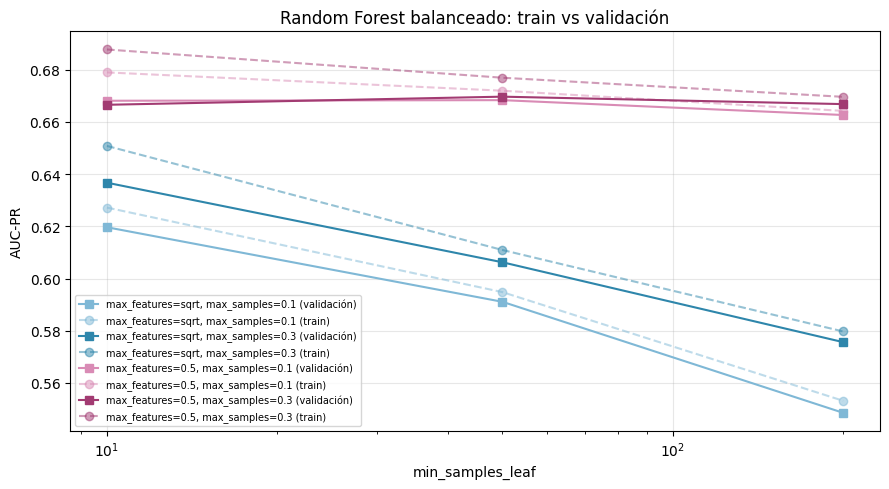

Combinaciones empatadas con el mejor AUC-PR: 1 de 12
Elegido: min_samples_leaf=50, max_features=0.5, max_samples=0.3


In [ ]:
UMBRAL = 0.5   # umbral por defecto, como en los papers (no se calibra)

def evaluar(y_true, p, umbral=UMBRAL):
    pred = (p >= umbral).astype(int)
    return {"auc_roc": roc_auc_score(y_true, p),
            "auc_pr": average_precision_score(y_true, p),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "accuracy": accuracy_score(y_true, pred)}

prep = construir_preprocesador().fit(X_tr)                      # fit SOLO con train
def a_densa(X):
    # preprocesador del proyecto -> matriz densa float32 (el Random Forest es mucho más rápido así)
    return prep.transform(X).toarray().astype(np.float32)
Xtr_d, Xval_d = a_densa(X_tr), a_densa(X_val)
print(f"Matriz de train: {Xtr_d.shape}, {Xtr_d.nbytes / 1e6:,.0f} MB")

filas, modelos = [], {}
for leaf in [10, 50, 200]:
    for mf in ["sqrt", 0.5]:
        for ms in [0.1, 0.3]:
            t0 = time.time()
            rf = RandomForestClassifier(n_estimators=50, min_samples_leaf=leaf, max_features=mf, max_samples=ms,
                                        class_weight="balanced", n_jobs=-1, random_state=SEMILLA).fit(Xtr_d, y_tr)
            seg_fit = time.time() - t0
            p_tr, p_val = rf.predict_proba(Xtr_d)[:, 1], rf.predict_proba(Xval_d)[:, 1]
            v = evaluar(y_val, p_val)
            modelos[(leaf, mf, ms)] = rf
            filas.append({"min_samples_leaf": leaf, "max_features": str(mf), "max_samples": ms,
                          "auc_pr_train": average_precision_score(y_tr, p_tr), "auc_pr_val": v["auc_pr"],
                          "auc_roc_val": v["auc_roc"],
                          "precision_val": v["precision"], "recall_val": v["recall"], "f1_val": v["f1"],
                          "accuracy_val": v["accuracy"],
                          "nodos_por_arbol": int(np.mean([e.tree_.node_count for e in rf.estimators_])),
                          "seg": seg_fit})
            print(f"leaf={leaf}, max_features={mf}, max_samples={ms}: AUC-PR val {v['auc_pr']:.4f} ({seg_fit:.0f} s)")
res = pd.DataFrame(filas)
display(res.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
colores = {("sqrt", 0.1): "#7FB8D6", ("sqrt", 0.3): "#2E86AB", ("0.5", 0.1): "#D98BB5", ("0.5", 0.3): "#A23B72"}
for (mf, ms), col in colores.items():
    d = res[(res.max_features == mf) & (res.max_samples == ms)]
    ax.plot(d.min_samples_leaf, d.auc_pr_val, "s-", color=col, label=f"max_features={mf}, max_samples={ms} (validación)")
    ax.plot(d.min_samples_leaf, d.auc_pr_train, "o--", color=col, alpha=.5, label=f"max_features={mf}, max_samples={ms} (train)")
ax.set_xscale("log"); ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("AUC-PR")
ax.set_title("Random Forest balanceado: train vs validación")
ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

empates = res[res["auc_pr_val"] >= res["auc_pr_val"].max() - 0.001].copy()
empates["p_mf"] = empates["max_features"].map({"sqrt": 0, "0.5": 1})
mejor = empates.sort_values(["min_samples_leaf", "p_mf", "max_samples"], ascending=[False, True, True]).iloc[0]
print(f"Combinaciones empatadas con el mejor AUC-PR: {len(empates)} de {len(res)}")
print(f"Elegido: min_samples_leaf={mejor['min_samples_leaf']}, max_features={mejor['max_features']}, max_samples={mejor['max_samples']}")

## 4. Modelo final y evaluación en test

El modelo final es el bosque elegido en la sección 3, ya entrenado con train, y se evalúa **una sola vez** en el test (2024–2025). Como referencia se incluye el baseline (regresión logística simple, `C=1`, sin balanceo), entrenado con los mismos datos.

In [ ]:
mf_final = "sqrt" if mejor["max_features"] == "sqrt" else float(mejor["max_features"])
rf_final = modelos[(int(mejor["min_samples_leaf"]), mf_final, float(mejor["max_samples"]))]
del modelos, Xtr_d, Xval_d; gc.collect()
baseline = Pipeline([("prep", construir_preprocesador()),
                     ("clf", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=SEMILLA))]).fit(X_tr, y_tr)

probas_te = {"Random Forest balanceado": rf_final.predict_proba(a_densa(X_te))[:, 1],
             "RL simple (baseline)": baseline.predict_proba(X_te)[:, 1]}
metricas = pd.DataFrame({k: evaluar(y_te, p) for k, p in probas_te.items()}).T
display(metricas.round(4))
print("Prevalencia en test (AUC-PR de un clasificador al azar):", round(y_te.mean(), 4))
for k, p in probas_te.items():
    cm = confusion_matrix(y_te, (p >= UMBRAL).astype(int))
    print(f"{k}: matriz de confusión [[TN FP], [FN TP]] = {cm.tolist()} | detecta {cm[1, 1]:,} de {int(y_te.sum()):,} casos")

,auc_roc,auc_pr,precision,recall,f1,accuracy
Random Forest balanceado,0.9107,0.6788,0.3385,0.7933,0.4745,0.8803
RL simple (baseline),0.9081,0.6774,0.8204,0.4732,0.6002,0.9570


Prevalencia en test (AUC-PR de un clasificador al azar): 0.0681
Random Forest balanceado: matriz de confusión [[TN FP], [FN TP]] = [[592938, 75828], [10107, 38800]] | detecta 38,800 de 48,907 casos
RL simple (baseline): matriz de confusión [[TN FP], [FN TP]] = [[663699, 5067], [25763, 23144]] | detecta 23,144 de 48,907 casos


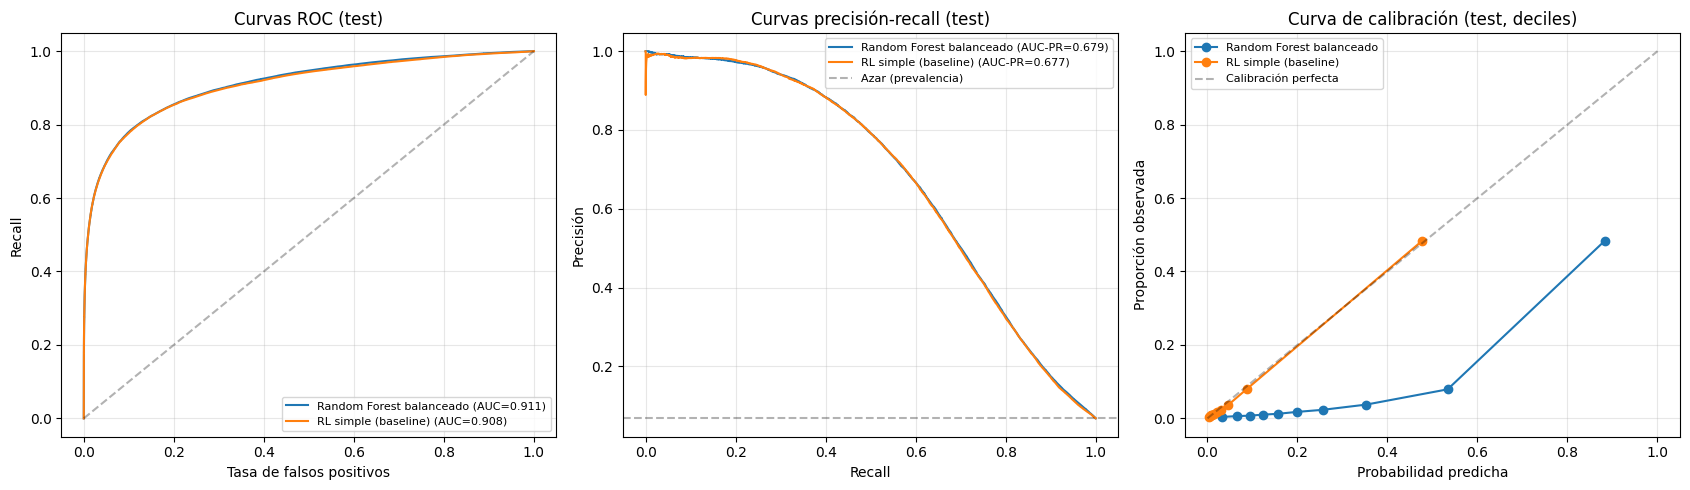

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k, p in probas_te.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{k} (AUC={roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rc, pr, label=f"{k} (AUC-PR={average_precision_score(y_te, p):.3f})")
    frac, media = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(media, frac, "o-", label=k)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.3)
axes[0].set(title="Curvas ROC (test)", xlabel="Tasa de falsos positivos", ylabel="Recall")
axes[1].axhline(y_te.mean(), color="k", ls="--", alpha=.3, label="Azar (prevalencia)")
axes[1].set(title="Curvas precisión-recall (test)", xlabel="Recall", ylabel="Precisión")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.3, label="Calibración perfecta")
axes[2].set(title="Curva de calibración (test, deciles)", xlabel="Probabilidad predicha", ylabel="Proporción observada")
for a in axes:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Interpretación

Las cifras corresponden a la ejecución en Colab; los valores exactos están en las tablas de arriba.

**1. `max_features` es el hiperparámetro que más importa.** Con `"sqrt"` (unas 7 columnas por corte) el AUC-PR en validación queda entre 0.55 y 0.64; con 0.5 (unas 26 columnas) sube a 0.663–0.670. La explicación más probable es que, con tan pocas columnas por corte, muchos cortes no tienen disponibles las variables más informativas (cada una es una sola columna entre 53, la mayoría categorías poco frecuentes del one-hot), y con 50 árboles el promedio no alcanza a compensarlo.

**2. `min_samples_leaf` muestra el equilibrio entre sobreajuste y subajuste.** Con hojas de 10 registros el AUC-PR de train (hasta 0.688) se separa del de validación (0.667): los árboles empiezan a memorizar ruido. Con 50 se obtiene el mejor AUC-PR en validación, y con 200 baja levemente porque los árboles pierden detalle. Es la forma esperada: ni muy detallado ni muy simple.

**3. `max_samples` aporta poco.** Con `max_features = 0.5` y hojas de 50, ver el 30% del train por árbol da un AUC-PR apenas mayor que ver el 10% (0.670 frente a 0.668), a cambio de triplicar el tiempo de entrenamiento.

**4. Modelo elegido:** `min_samples_leaf = 50`, `max_features = 0.5`, `max_samples = 0.3`. Es la única combinación dentro de la tolerancia de 0.001 del mejor AUC-PR en validación.

**5. En test, el Random Forest discrimina apenas mejor que el baseline.** Su AUC-ROC es 0.911 frente a 0.908 y su AUC-PR 0.679 frente a 0.677. Es el único modelo hasta ahora que queda por encima del baseline en ambas métricas, pero la diferencia es muy pequeña (0.003 y 0.001) y las curvas ROC y precisión-recall casi se superponen. La flexibilidad de los árboles (relaciones no lineales e interacciones) aporta poco sobre la regresión logística con estas 9 variables.

**6. Punto de operación con el umbral 0.5.** Por el balanceo, el Random Forest se comporta como la regresión logística balanceada: detecta 38 800 de 48 907 casos (recall 0.79) con 75 828 falsas alarmas, unas 2.0 por cada caso real (precisión 0.34, F1 0.47). Frente a la regresión logística balanceada (recall 0.81, precisión 0.31, F1 0.45, unas 87 900 falsas alarmas), consigue un recall similar con unas 12 000 falsas alarmas menos.

**7. Las probabilidades quedan infladas.** En el decil de mayor riesgo el bosque predice en promedio cerca de 0.88, pero la proporción observada de bajo peso es cercana a 0.48. Como en la regresión balanceada, es consecuencia de `class_weight="balanced"`; para usarlas como riesgo absoluto habría que recalibrarlas.

**8. Comparación con Almeida et al. (2026).** En ese estudio el random forest rindió peor que la regresión logística (AUC-ROC 0.81 sin balanceo y 0.78 con balanceo, frente a 0.85). Aquí el random forest balanceado queda al nivel de la regresión logística o levemente por encima (0.911 frente a 0.908). Las diferencias pueden venir de los datos (otras variables y prevalencia) y del ajuste de hiperparámetros, que Almeida no reporta.

**9. Costo.** La grilla tomó unos 35 minutos en Colab, frente a segundos de la regresión logística simple, para una mejora de 0.003 en AUC-ROC.

## 6. Limitaciones

- **`DUR_EMB_PARTO` se conoce al momento del parto, no antes.** El encuadre es "información registrada al momento del parto, antes del pesaje"; no es una predicción prenatal.
- **Umbral fijo en 0.5**, como en los papers. Precisión, recall y F1 dependen de esa elección; AUC-ROC y AUC-PR no.
- **La prevalencia del test (6.81%) es mayor que la de train (6.32%).** Precisión y F1 en test no son directamente comparables con validación.
- **El peso tiene redondeo en 2500 g** (16 353 registros exactos), lo que mete ruido en la etiqueta justo en el umbral.
- **El test no incluye diciembre de 2025.**
- **El CNV no registra variables clínicas** (controles prenatales, anemia, hipertensión, IMC), que podrían mejorar la predicción.
- `n_estimators` quedó fijo en 50 por tiempo; con más árboles el AUC-PR mejoraría muy poco.
- No se ajustaron `max_depth`, `criterion` ni `class_weight` (fijo en `"balanced"`). En los árboles, el balanceo puede reducir la capacidad de discriminar: en Almeida et al. el AUC-ROC del random forest bajó de 0.81 a 0.78 al balancear.
- Las probabilidades de un Random Forest balanceado no están calibradas; para usarlas como riesgo absoluto habría que recalibrarlas.
- Una sola partición de validación y una sola semilla.